# 03 - LSTM encoder-decoder: M0, M1 and M1b

**Goal of this notebook.** Build the first real models and the tools to train and judge them.

| Model | Description |
|---|---|
| M0 | no learning: always writes the most frequent query shape (a floor) |
| M1 | LSTM encoder, LSTM decoder, no attention: **the required baseline** |
| M1b | like M1, but the encoder reads the input in both directions |


Files written by this notebook:

| File | Role |
|---|---|
| `src/t2s/eval/metrics.py`, `src/t2s/eval/baseline.py` | how a model is judged; the baseline M0 |
| `src/t2s/models/lstm_cell.py` | the LSTM cell, written from its equations |
| `src/t2s/models/encoder.py`, `decoder.py`, `seq2seq.py` | the encoder, the decoder, and the whole model |
| `src/t2s/decoding/greedy.py` | greedy decoding |
| `src/t2s/evaluate.py` | evaluation of a trained model |
| `src/t2s/train.py` | the training loop |
| `configs/m1.yaml`, `configs/m1b.yaml` | the settings of each experiment |
| `scripts/train.py` | the same training from the command line |

Tools from earlier notebooks that are used here:

| Tool | What it does | Where it is explained |
|---|---|---|
| `load_split`, `Example`, `db_path` | load the data | notebook 01, section 4 |
| `Query`, `Query.canonical` | a query; a form to compare queries | notebook 01, section 3 |
| `SqliteExecutor` | runs a query on the database | notebook 01, section 6 |
| `source_tokens`, `target_tokens`, `parse_target` | the format of the input and output; the way back to a query | notebook 02, section 2 |
| `Vocab`, `build_vocab` | the vocabulary | notebook 02, sections 3 and 4 |
| `encode_example`, `make_batches`, `collate` | ids, batches, padded tensors | notebook 02, section 4 |
| `PlainCodec` | the vocabulary, the encoding of examples and the decoding of outputs, in one object | notebook 02, section 4.4 |

## Setup


In [65]:
import json, os, sys
from pathlib import Path

NOTEBOOK_NUMBER = 3
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/text2sql")
    CODE = "/content/code"                                      # where the notebooks write their code
    DATA_ROOT = "/content/data"                                 # the dataset (downloaded in each session)
    CKPT_DIR = "/content/drive/MyDrive/text2sql_checkpoints"    # the saved models
else:
    PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    CODE, DATA_ROOT, CKPT_DIR = str(PROJECT / "code"), str(PROJECT / "data"), str(PROJECT / "checkpoints")
os.chdir(PROJECT)   # the results are saved in the folder "results" of the project
os.makedirs(CKPT_DIR, exist_ok=True)


def rebuild_code(before):
    """Write again the code files of the notebooks 01 ... before-1 (their writefile cells)."""
    for path in sorted((PROJECT / "notebooks").glob("[0-9][0-9]_*.ipynb")):
        if int(path.name[:2]) >= before:
            continue
        for cell in json.loads(path.read_text())["cells"]:
            source = "".join(cell["source"])
            if cell["cell_type"] != "code" or not source.startswith("%%writefile"):
                continue
            first_line, _, body = source.partition("\n")
            words = first_line.split()
            target = Path(words[-1].replace("{CODE}", CODE))
            target.parent.mkdir(parents=True, exist_ok=True)
            with open(target, "a" if words[1] == "-a" else "w") as f:
                f.write(body if body.endswith("\n") else body + "\n")


for folder in ["src/t2s/data", "src/t2s/models", "src/t2s/decoding", "src/t2s/eval", "scripts", "configs"]:
    os.makedirs(f"{CODE}/{folder}", exist_ok=True)
rebuild_code(NOTEBOOK_NUMBER)
for package in ["src/t2s", "src/t2s/data", "src/t2s/models", "src/t2s/decoding", "src/t2s/eval"]:
    Path(f"{CODE}/{package}/__init__.py").touch()
sys.path.insert(0, f"{CODE}/src")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:

import json
from pathlib import Path
import torch
from t2s.data.download import download_wikisql
from t2s.data.wikisql import load_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

data_dir = download_wikisql(DATA_ROOT)
splits = {name: load_split(data_dir, name) for name in ["train", "dev"]}
print({name: len(examples) for name, examples in splits.items()})

device: cuda
{'train': 56355, 'dev': 8421}


## 1. How a model is judged, and the baseline M0

Before building models, I define how to judge them. A model writes an output sequence; I turn it back into a query and compare it
with the gold query in two ways:

- **exact match**: the query is the same as the gold query (the order of the conditions does not matter);
- **execution accuracy**: the query gives the same *answer* as the gold query on the table.

Both are needed. A query can be written differently and still give the right answer. The opposite also happens: two different
wrong queries can both return an empty answer and look equal.

**The definitions** are in the docstring: an output is *valid* if it follows the format and names columns of the table;
*executable* if the query runs without an error; *correct* if it gives the same answer as the gold query.

In [7]:
%%writefile {CODE}/src/t2s/eval/metrics.py
"""Query-level metrics: exact match and execution accuracy.

For each example the model's output (a list of tokens) is turned back into a query. Then:

    valid       the output follows the format and names columns of the table
    exact       the query equals the gold query (order of the conditions ignored)
    executable  the query ran on the database without an error
    correct     the query gives the same answer as the gold query

A query can be written differently and still give the right answer, which is why both
exact match and execution accuracy are reported. The opposite also happens: two wrong
queries can both return an empty answer and look equal. `gold_empty` marks the examples
whose gold answer is empty, so accuracy can also be given without them.
"""

from dataclasses import dataclass

from t2s.data.format import parse_target
from t2s.data.wikisql import Example
from t2s.eval.executor import SqliteExecutor
from t2s.query import Query




Writing /content/code/src/t2s/eval/metrics.py


**`Prediction`** records what happened to one example: the output tokens, the parsed query (or `None`), and the four yes/no results.
`gold_empty` marks the examples whose gold answer is empty (see the observation in notebook 01).

In [8]:
%%writefile -a {CODE}/src/t2s/eval/metrics.py
@dataclass(frozen=True)
class Prediction:
    tokens: list[str]
    query: Query | None
    exact: bool
    executable: bool
    correct: bool
    gold_empty: bool




Appending to /content/code/src/t2s/eval/metrics.py


**`is_empty`** says if an answer is empty (no row, or a single `None`).

In [9]:
%%writefile -a {CODE}/src/t2s/eval/metrics.py
def is_empty(answer: list) -> bool:
    return len(answer) == 0 or answer == [None]




Appending to /content/code/src/t2s/eval/metrics.py


**`score`** judges the outputs of a model. For each example it runs the gold query; turns the output tokens into a query with
`parse_target` (`None` means an invalid output); compares it with the gold query (`exact`); runs it, counting an error as
not executable; and compares the answers (`correct`). Then it computes the rates over all examples, and also the execution accuracy
without the questions whose gold answer is empty.

In [10]:
%%writefile -a {CODE}/src/t2s/eval/metrics.py
def score(
    examples: list[Example], outputs: list[list[str]], executor: SqliteExecutor
) -> tuple[dict, list[Prediction]]:
    """Score the outputs of a model. Returns the metrics and one `Prediction` per example."""
    predictions = []
    for ex, tokens in zip(examples, outputs):
        gold_answer = executor.execute(ex.table_id, ex.query)
        query = parse_target(tokens, ex.header, ex.question)

        exact = executable = correct = False
        if query is not None:
            exact = query.canonical() == ex.query.canonical()
            try:
                answer = executor.execute(ex.table_id, query)
                executable = True
                correct = answer == gold_answer
            except Exception:
                pass
        predictions.append(
            Prediction(tokens, query, exact, executable, correct, is_empty(gold_answer))
        )

    n = len(predictions)
    non_empty = [p for p in predictions if not p.gold_empty]
    metrics = {
        "n": n,
        "exact_match": sum(p.exact for p in predictions) / n,
        "execution_accuracy": sum(p.correct for p in predictions) / n,
        "execution_accuracy_gold_not_empty": sum(p.correct for p in non_empty) / len(non_empty),
        "valid_format": sum(p.query is not None for p in predictions) / n,
        "executable": sum(p.executable for p in predictions) / n,
    }
    return metrics, predictions


Appending to /content/code/src/t2s/eval/metrics.py


**M0** writes the same query for every question: the most frequent aggregator and the most frequent selected column of the training
set, and no condition. It does not read the question, so it shows what a model gets for free and what the other models must beat.

In [11]:
%%writefile {CODE}/src/t2s/eval/baseline.py
"""M0: the baseline that does not learn.

It writes the same query shape for every question: the most frequent aggregator and the
most frequent selected column of the training set, with no condition. It shows what a
model gets without reading the question, and so what the other models must beat.
"""

from collections import Counter

from t2s.data.format import target_tokens
from t2s.data.wikisql import Example
from t2s.eval.executor import SqliteExecutor
from t2s.eval.metrics import score
from t2s.query import Query




Writing /content/code/src/t2s/eval/baseline.py


**`baseline_outputs`** gives the output tokens of M0 for every example. (A table can have fewer columns than the usual index, so
the index is limited to the columns of the table.)

In [12]:
%%writefile -a {CODE}/src/t2s/eval/baseline.py
def baseline_outputs(train: list[Example], examples: list[Example]) -> list[list[str]]:
    """The output tokens of M0 for every example."""
    agg = Counter(ex.query.agg for ex in train).most_common(1)[0][0]
    select = Counter(ex.query.select for ex in train).most_common(1)[0][0]
    outputs = []
    for ex in examples:
        column = min(select, len(ex.header) - 1)  # a table may have fewer columns
        outputs.append(target_tokens(Query(select=column, agg=agg), ex.header))
    return outputs




Appending to /content/code/src/t2s/eval/baseline.py


**`evaluate_baseline`** judges M0 with the same metrics as the trained models.

In [13]:
%%writefile -a {CODE}/src/t2s/eval/baseline.py
def evaluate_baseline(
    train: list[Example], examples: list[Example], executor: SqliteExecutor
) -> dict:
    """Metrics of M0 on `examples` (same metrics as for the trained models)."""
    metrics, _ = score(examples, baseline_outputs(train, examples), executor)
    return metrics


Appending to /content/code/src/t2s/eval/baseline.py


In [14]:
from t2s.data.wikisql import db_path
from t2s.eval.executor import SqliteExecutor
from t2s.eval.baseline import baseline_outputs, evaluate_baseline

for ex, tokens in zip(splits["dev"][:3], baseline_outputs(splits["train"], splits["dev"][:3])):
    print("question :", ex.question.strip())
    print("M0 writes:", " ".join(tokens))
    print("gold     :", ex.query.to_sql(ex.header))
    print()

dev_executor = SqliteExecutor(db_path(data_dir, "dev"))
m0 = evaluate_baseline(splits["train"], splits["dev"], dev_executor)
Path("results/m0").mkdir(parents=True, exist_ok=True)
Path("results/m0/metrics.json").write_text(json.dumps({"name": "m0", "parameters": 0, "dev": m0}, indent=2))
print({key: round(value, 4) for key, value in m0.items()})

question : What position does the player who played for butler cc (ks) play?
M0 writes: <sel> <agg_none> years in toronto
gold     : SELECT Position FROM table WHERE School/Club Team = 'Butler CC (KS)'

question : How many schools did player number 3 play at?
M0 writes: <sel> <agg_none> years in toronto
gold     : SELECT COUNT(School/Club Team) FROM table WHERE No. = '3'

question : What school did player number 21 play for?
M0 writes: <sel> <agg_none> years in toronto
gold     : SELECT School/Club Team FROM table WHERE No. = '21'

{'n': 8421, 'exact_match': 0.0, 'execution_accuracy': 0.0001, 'execution_accuracy_gold_not_empty': 0.0001, 'valid_format': 1.0, 'executable': 1.0}


**What I observe.** M0 writes the same short query for every question, so its output is always in the right format
(`valid_format` = 1.0) but it is almost never right: **0.0% exact match and 0.01% execution accuracy** on dev. This is the floor.
Reading the question is necessary.

## 2. The LSTM cell

An LSTM is a network that reads a sequence one step at a time and keeps a memory. I write the cell myself from its equations, to
understand it, and I test it against the cell of PyTorch.

**The idea.** At each step the cell reads an input `x` and its previous state: `h` (the hidden state, what the cell shows) and
`c` (the memory, what it remembers). Four *gates* decide what to do:

- the **input gate** `i`: how much new information to write in the memory;
- the **forget gate** `f`: how much of the old memory to keep;
- the **candidate** `g`: the new information;
- the **output gate** `o`: how much of the memory to show.

The equations are in the docstring below. `sigmoid` gives a number between 0 and 1 ("how much"), and `tanh` gives a number between
-1 and 1.

In [15]:
%%writefile {CODE}/src/t2s/models/lstm_cell.py
"""An LSTM cell written from its equations.

At each step the cell reads an input x and its previous state (h, c):

    i = sigmoid(W_i x + U_i h + b_i)      input gate: how much new information to write
    f = sigmoid(W_f x + U_f h + b_f)      forget gate: how much of the old memory to keep
    g = tanh   (W_g x + U_g h + b_g)      candidate: the new information
    o = sigmoid(W_o x + U_o h + b_o)      output gate: how much of the memory to show

    c' = f * c + i * g                    new memory
    h' = o * tanh(c')                     new hidden state

The four gates are computed together with one matrix product and then split.
The order of the gates (i, f, g, o) is the same as in `torch.nn.LSTMCell`, which lets
the tests compare the two cells.
"""

import torch
from torch import nn




Writing /content/code/src/t2s/models/lstm_cell.py


**`__init__`.** Two linear layers: `w_x` applies the weights `W` to the input (and adds the bias `b`), and `w_h` applies `U` to the
previous hidden state. Each gives `4 * hidden_size` numbers: the four gates side by side, so one product computes all of them.

In [16]:
%%writefile -a {CODE}/src/t2s/models/lstm_cell.py
class LSTMCell(nn.Module):
    def __init__(self, input_size: int, hidden_size: int):
        super().__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.w_x = nn.Linear(input_size, 4 * hidden_size)  # W and the bias b
        self.w_h = nn.Linear(hidden_size, 4 * hidden_size, bias=False)  # U
        self.reset_parameters()



Appending to /content/code/src/t2s/models/lstm_cell.py


**`reset_parameters`** sets the starting values: Xavier for `W`, orthogonal for `U` (this keeps the signal stable from step to step),
zero for the biases, except the forget-gate bias, which starts at 1, so that the cell remembers by default at the start of training.

In [17]:
%%writefile -a {CODE}/src/t2s/models/lstm_cell.py
    def reset_parameters(self) -> None:
        nn.init.xavier_uniform_(self.w_x.weight)
        nn.init.orthogonal_(self.w_h.weight)
        nn.init.zeros_(self.w_x.bias)
        # A forget-gate bias of 1 makes the cell remember at the start of training.
        with torch.no_grad():
            self.w_x.bias[self.hidden_size : 2 * self.hidden_size].fill_(1.0)



Appending to /content/code/src/t2s/models/lstm_cell.py


**`forward`** is one step. It computes the four gates, applies `sigmoid` to `i`, `f`, `o` and `tanh` to `g`, then:

- new memory `c' = f * c + i * g` (keep a part of the old memory, add a part of the new information);
- new hidden state `h' = o * tanh(c')`.

In [18]:
%%writefile -a {CODE}/src/t2s/models/lstm_cell.py
    def forward(
        self, x: torch.Tensor, state: tuple[torch.Tensor, torch.Tensor]
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """x: (B, input_size); state: (h, c), each (B, hidden_size)."""
        h, c = state
        gates = self.w_x(x) + self.w_h(h)  # (B, 4H)
        i, f, g, o = gates.chunk(4, dim=-1)
        i, f, o = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o)
        g = torch.tanh(g)
        c_new = f * c + i * g
        h_new = o * torch.tanh(c_new)
        return h_new, c_new



Appending to /content/code/src/t2s/models/lstm_cell.py


**`load_from_torch`** copies the weights of PyTorch's `nn.LSTMCell`, only to test that both cells give the same result. (PyTorch keeps two
bias vectors, I keep one, so I give it their sum.)

In [19]:
%%writefile -a {CODE}/src/t2s/models/lstm_cell.py
    @torch.no_grad()
    def load_from_torch(self, cell: nn.LSTMCell) -> None:
        """Copy the weights of a `torch.nn.LSTMCell` (used by the tests)."""
        self.w_x.weight.copy_(cell.weight_ih)
        self.w_h.weight.copy_(cell.weight_hh)
        self.w_x.bias.copy_(cell.bias_ih + cell.bias_hh)  # PyTorch keeps two biases


Appending to /content/code/src/t2s/models/lstm_cell.py


In [20]:
from torch import nn
from t2s.models.lstm_cell import LSTMCell

torch.manual_seed(0)
reference = nn.LSTMCell(5, 8)   # the cell of PyTorch
mine = LSTMCell(5, 8)           # my cell
mine.load_from_torch(reference) # same weights in both

x, h, c = torch.randn(3, 5), torch.randn(3, 8), torch.randn(3, 8)
h_ref, c_ref = reference(x, (h, c))
h_own, c_own = mine(x, (h, c))
print("largest difference in h:", (h_ref - h_own).abs().max().item())
print("largest difference in c:", (c_ref - c_own).abs().max().item())

largest difference in h: 2.9802322387695312e-08
largest difference in c: 1.1920928955078125e-07


**What I observe.** With the same weights, my cell and the cell of PyTorch give the same results up to rounding errors (about
`1e-7`). So my cell computes what the equations say.

## 3. The encoder

The encoder reads the input sequence and builds a representation of it.

**The idea.** `ids -> embedding -> LSTM -> states`. The embedding turns each id into a vector of numbers (learned during training).
The LSTM reads the vectors and gives one state per position and a final state.

A **bidirectional** encoder has two LSTMs: one reads left to right, the other right to left, and their states are joined. Then each
position knows what is before it and what is after it, and its state has size `2H`.

The batch is padded, so the true lengths are given to the LSTM (*packed sequences*): it stops at the real end of each input and the
final state is not changed by the padding.

In [21]:
%%writefile {CODE}/src/t2s/models/encoder.py
"""The encoder: reads the input sequence and summarizes it.

    ids (B, T) -> embedding (B, T, E) -> LSTM -> states (B, T, D*H) and a final state

D is 2 for a bidirectional encoder (one LSTM reads left to right, another right to left,
and their states are joined), 1 otherwise.

The batch is padded, so the LSTM is given the true lengths (packed sequences). It then
stops at the real end of each sequence and the final state is not polluted by padding.
"""

import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence




Writing /content/code/src/t2s/models/encoder.py


**`__init__`.** The embedding table (`padding_idx` keeps the vector of `<pad>` at zero), dropout, and the LSTM. For the encoder I use
PyTorch's `nn.LSTM`, which is fast on a GPU, since my own cell has been shown above to compute the same thing.

In [22]:
%%writefile -a {CODE}/src/t2s/models/encoder.py
class Encoder(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        emb_dim: int,
        hidden: int,
        num_layers: int,
        bidirectional: bool,
        dropout: float,
        pad_id: int,
    ):
        super().__init__()
        self.hidden = hidden
        self.num_layers = num_layers
        self.directions = 2 if bidirectional else 1
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_id)
        self.dropout = nn.Dropout(dropout)
        self.rnn = nn.LSTM(
            emb_dim,
            hidden,
            num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=dropout if num_layers > 1 else 0.0,
        )



Appending to /content/code/src/t2s/models/encoder.py


**`out_dim`** is the size of each state: the hidden size times the number of directions.

In [23]:
%%writefile -a {CODE}/src/t2s/models/encoder.py
    @property
    def out_dim(self) -> int:
        return self.hidden * self.directions



Appending to /content/code/src/t2s/models/encoder.py


**`forward`** embeds the ids, packs the batch with the true lengths, runs the LSTM, and unpacks the result. It returns the states of
every position, shape `(B, T, D*H)`, and the final state `(h, c)`, each of shape `(layers * D, B, H)`. (Attention, in notebook 04, uses
the states of all the positions.)

In [24]:
%%writefile -a {CODE}/src/t2s/models/encoder.py
    def forward(
        self, src: torch.Tensor, src_len: torch.Tensor
    ) -> tuple[torch.Tensor, tuple[torch.Tensor, torch.Tensor]]:
        """src: (B, T) ids, src_len: (B,) real lengths.

        Returns the states of every position (B, T, D*H) and the final (h, c), each of
        shape (layers * D, B, H).
        """
        embedded = self.dropout(self.embedding(src))
        packed = pack_padded_sequence(embedded, src_len.cpu(), batch_first=True, enforce_sorted=False)
        packed_out, (h, c) = self.rnn(packed)
        out, _ = pad_packed_sequence(packed_out, batch_first=True, total_length=src.size(1))
        return out, (h, c)


Appending to /content/code/src/t2s/models/encoder.py


In [25]:
from t2s.models.encoder import Encoder

encoder = Encoder(vocab_size=50, emb_dim=16, hidden=24, num_layers=1, bidirectional=True, dropout=0.0, pad_id=0).eval()
src = torch.randint(3, 50, (3, 7))
src_len = torch.tensor([7, 5, 3])
src[1, 5:] = 0   # padding after the real end of the second input
src[2, 3:] = 0

states, (h, c) = encoder(src, src_len)
print("states of every position:", tuple(states.shape), "   final h:", tuple(h.shape))

# The second input, encoded alone (no padding), must give the same states.
alone, _ = encoder(src[1:2, :5], torch.tensor([5]))
print("same states with and without padding:", torch.allclose(states[1, :5], alone[0], atol=1e-5))

states of every position: (3, 7, 48)    final h: (2, 3, 24)
same states with and without padding: True


**What I observe.** For 3 inputs of 7 positions, the encoder gives a state of size 48 (2 directions x 24) for each position, and a final
state per direction. An input gives **the same states with or without padding**, so the padding does not disturb the encoder.

## 4. The decoder

**The idea.** The decoder writes the output one token at a time. At each step: `previous token -> embedding -> LSTM layers -> hidden state
-> one score per word of the vocabulary`. This file contains **one step**; the loop over the steps is in `Seq2Seq` (training) and in
`greedy.py` (generation).

In [26]:
%%writefile {CODE}/src/t2s/models/decoder.py
"""The decoder: writes the output sequence one token at a time.

At every step it receives the previous token, updates its state, and gives one score per
word of the vocabulary:

    previous token (B,) -> embedding (B, E) -> LSTM layers -> hidden (B, H) -> scores (B, V)

The loop over the steps is in `Seq2Seq` (training) and in `decoding/` (generation), because
both use `step`.
"""

import torch
from torch import nn

from t2s.models.lstm_cell import LSTMCell




Writing /content/code/src/t2s/models/decoder.py


**`__init__`.** An embedding table, dropout, one of **my** LSTM cells for each layer, and an output layer that turns the hidden state
(`hidden` numbers) into `vocab_size` scores.

In [27]:
%%writefile -a {CODE}/src/t2s/models/decoder.py
class Decoder(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        emb_dim: int,
        hidden: int,
        num_layers: int,
        dropout: float,
        pad_id: int,
    ):
        super().__init__()
        self.hidden = hidden
        self.num_layers = num_layers
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_id)
        self.dropout = nn.Dropout(dropout)
        self.cells = nn.ModuleList(
            LSTMCell(emb_dim if layer == 0 else hidden, hidden) for layer in range(num_layers)
        )
        self.out = nn.Linear(hidden, vocab_size)



Appending to /content/code/src/t2s/models/decoder.py


**`step`.** It embeds the previous token and passes it through the layers (the output of a layer is the input of the next one). The
last hidden state goes through the output layer and gives the scores of the next token. It returns the scores and the new state.

In [28]:
%%writefile -a {CODE}/src/t2s/models/decoder.py
    def step(
        self, token: torch.Tensor, state: tuple[torch.Tensor, torch.Tensor]
    ) -> tuple[torch.Tensor, tuple[torch.Tensor, torch.Tensor]]:
        """One decoding step.

        token: (B,) ids of the previous output token.
        state: (h, c), each (layers, B, H).
        Returns the scores (B, V) for the next token and the new state.
        """
        h, c = state
        x = self.dropout(self.embedding(token))
        new_h, new_c = [], []
        for layer, cell in enumerate(self.cells):
            h_layer, c_layer = cell(x, (h[layer], c[layer]))
            new_h.append(h_layer)
            new_c.append(c_layer)
            x = self.dropout(h_layer)  # input of the next layer, then of the output layer
        return self.out(x), (torch.stack(new_h), torch.stack(new_c))


Appending to /content/code/src/t2s/models/decoder.py


## 5. The whole model: `Seq2Seq`

`Seq2Seq` connects the encoder and the decoder.

**The idea.** `input -> encoder -> final state -> decoder -> scores`. The decoder starts from the final state of the encoder. This state
is the **only link** between reading and writing, so everything the decoder knows about the input has to fit in it. (This is the weakness
that attention, in notebook 04, removes.)

With a bidirectional encoder the final state has two parts (one per direction). They are joined and mapped back to size `H` by a linear
layer, the *bridge*, so the decoder has the same size in all variants.

In [29]:
%%writefile {CODE}/src/t2s/models/seq2seq.py
"""The encoder-decoder model (M1 and M1b: no attention).

    input -> Encoder -> final state -> (bridge) -> initial decoder state -> Decoder -> scores

The decoder starts from the final state of the encoder. This state is the only link between
reading and writing, so everything the decoder knows about the input has to fit in it.

With a bidirectional encoder the final state has two parts (left-to-right and
right-to-left) of size H each. They are joined and mapped back to size H by a linear layer
("bridge"), so the decoder has the same size in all variants.
"""

import torch
from torch import nn

from t2s.models.decoder import Decoder
from t2s.models.encoder import Encoder




Writing /content/code/src/t2s/models/seq2seq.py


**`__init__`** builds the encoder, the decoder, and (only for a bidirectional encoder) the two bridge layers.

In [30]:
%%writefile -a {CODE}/src/t2s/models/seq2seq.py
class Seq2Seq(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        pad_id: int,
        emb_dim: int = 256,
        hidden: int = 256,
        num_layers: int = 1,
        bidirectional: bool = False,
        dropout: float = 0.3,
    ):
        super().__init__()
        self.encoder = Encoder(vocab_size, emb_dim, hidden, num_layers, bidirectional, dropout, pad_id)
        self.decoder = Decoder(vocab_size, emb_dim, hidden, num_layers, dropout, pad_id)
        self.num_layers = num_layers
        self.hidden = hidden
        self.bridge_h = self.bridge_c = None
        if bidirectional:
            self.bridge_h = nn.Linear(2 * hidden, hidden)
            self.bridge_c = nn.Linear(2 * hidden, hidden)



Appending to /content/code/src/t2s/models/seq2seq.py


**`_decoder_state`** turns the final state of the encoder into the starting state of the decoder. PyTorch gives it as
`(layers * directions, B, H)`; I regroup it by layer, join the two directions, and apply the bridge when there are two directions
(`tanh` for `h`, nothing for `c`).

In [31]:
%%writefile -a {CODE}/src/t2s/models/seq2seq.py
    def _decoder_state(
        self, enc_state: tuple[torch.Tensor, torch.Tensor]
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """Final encoder state (layers*D, B, H) -> initial decoder state (layers, B, H)."""
        h, c = enc_state
        directions = self.encoder.directions
        batch = h.size(1)

        def join(x: torch.Tensor) -> torch.Tensor:
            x = x.view(self.num_layers, directions, batch, self.hidden)
            return x.permute(0, 2, 1, 3).reshape(self.num_layers, batch, directions * self.hidden)

        h, c = join(h), join(c)
        if self.bridge_h is not None:
            h, c = torch.tanh(self.bridge_h(h)), self.bridge_c(c)
        return h, c



Appending to /content/code/src/t2s/models/seq2seq.py


**`init_decode`** reads the input and gives the starting state of the decoder. `memory` is what the decoder may need at every step
besides its state; it is empty here, and the attention models will put the encoder states in it.

In [32]:
%%writefile -a {CODE}/src/t2s/models/seq2seq.py
    def init_decode(self, src: torch.Tensor, src_len: torch.Tensor):
        """Read the input. Returns (initial decoder state, memory).

        `memory` is what the decoder may need at every step besides its state. It is None
        for models without attention.
        """
        _, enc_state = self.encoder(src, src_len)
        return self._decoder_state(enc_state), None



Appending to /content/code/src/t2s/models/seq2seq.py


**`step`** is one decoding step (it calls the decoder).

In [33]:
%%writefile -a {CODE}/src/t2s/models/seq2seq.py
    def step(self, token: torch.Tensor, state, memory):
        return self.decoder.step(token, state)



Appending to /content/code/src/t2s/models/seq2seq.py


**`forward`** is the training pass: it runs the loop over the output positions. At each position it gets the scores and chooses the
next input: the **true** previous token (*teacher forcing*) or, with probability `1 - teacher_forcing`, the model's own prediction.
It returns the scores of all positions, shape `(B, U, V)`.

In [34]:
%%writefile -a {CODE}/src/t2s/models/seq2seq.py
    def forward(
        self,
        src: torch.Tensor,
        src_len: torch.Tensor,
        tgt_in: torch.Tensor,
        teacher_forcing: float = 1.0,
    ) -> torch.Tensor:
        """Scores for every output position, shape (B, U, V).

        tgt_in: (B, U) decoder inputs (<sos> and the target without its last token).
        teacher_forcing: probability, at each step, of feeding the true previous token.
            With 1.0 the true token is always used. Otherwise the model's own
            prediction is used with probability 1 - teacher_forcing.
        """
        state, memory = self.init_decode(src, src_len)
        batch, length = tgt_in.shape
        token = tgt_in[:, 0]
        all_scores = []
        for t in range(length):
            scores, state = self.step(token, state, memory)
            all_scores.append(scores)
            if t + 1 < length:
                if teacher_forcing >= 1.0:
                    token = tgt_in[:, t + 1]
                else:
                    use_true = torch.rand(batch, device=tgt_in.device) < teacher_forcing
                    token = torch.where(use_true, tgt_in[:, t + 1], scores.argmax(dim=-1))
        return torch.stack(all_scores, dim=1)




Appending to /content/code/src/t2s/models/seq2seq.py


**`count_parameters`** counts the numbers the model can learn.

In [35]:
%%writefile -a {CODE}/src/t2s/models/seq2seq.py
def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


Appending to /content/code/src/t2s/models/seq2seq.py


### Check 1: the first loss

A model that knows nothing gives about the same probability, `1 / V`, to every word. Its cross-entropy loss is then `-log(1/V) = ln(V)`.
The loss of a new model must be close to this number. If it is not, something is wrong before any training.

In [36]:
import math
import torch.nn.functional as F
from t2s.data.dataset import build_vocab, encode_example, collate
from t2s.models.seq2seq import Seq2Seq, count_parameters

vocab = build_vocab(splits["train"], min_freq=2)
encoded = [encode_example(e, vocab) for e in splits["train"][:64]]
batch = {k: v.to(device) for k, v in collate(encoded, vocab.pad_id).items()}

torch.manual_seed(0)
model = Seq2Seq(len(vocab), vocab.pad_id, emb_dim=256, hidden=256, dropout=0.0).to(device)
scores = model(batch["src"], batch["src_len"], batch["tgt_in"])
loss = F.cross_entropy(scores.reshape(-1, len(vocab)), batch["tgt_out"].reshape(-1), ignore_index=vocab.pad_id)

print(f"tensor shapes: input {tuple(batch['src'].shape)}, decoder input {tuple(batch['tgt_in'].shape)}, scores {tuple(scores.shape)}")
print(f"vocabulary size V = {len(vocab)}")
print(f"expected loss of a model that knows nothing: ln(V) = {math.log(len(vocab)):.2f}")
print(f"measured loss of the new model              : {loss.item():.2f}")
print(f"parameters: {count_parameters(model):,}")

in_vocabulary = sum(p.numel() for name, p in model.named_parameters() if "embedding" in name or name.startswith("decoder.out"))
print(f"{in_vocabulary:,} of them ({in_vocabulary / count_parameters(model):.0%}) belong to the vocabulary (two embedding tables and the output layer)")

tensor shapes: input (64, 53), decoder input (64, 25), scores (64, 25, 15962)
vocabulary size V = 15962
expected loss of a model that knows nothing: ln(V) = 9.68
measured loss of the new model              : 9.70
parameters: 13,326,426
12,274,778 of them (92%) belong to the vocabulary (two embedding tables and the output layer)


In [ ]:
!grep -n "^class \|    def \|^def " {CODE}/src/t2s/models/seq2seq.py

20:class Seq2Seq(nn.Module):
21:    def __init__(
41:    def _decoder_state(
49:        def join(x: torch.Tensor) -> torch.Tensor:
58:    def init_decode(self, src: torch.Tensor, src_len: torch.Tensor):
67:    def step(self, token: torch.Tensor, state, memory):
70:    def forward(
100:def count_parameters(model: nn.Module) -> int:


**What I observe.**

- The scores have the shape `(64, 25, 15962)`: 64 examples, 25 output positions, one score for each of the 15,962 words.
- The expected loss is `ln(15962) = 9.68` and the measured loss is **9.70**: the new model knows nothing, as it should.
- The model has **13,326,426 parameters, and 92% of them belong to the vocabulary** (the two embedding tables and the output layer).
  The LSTMs hold only about one million. So the size of this model is dominated by the vocabulary, not by the recurrent layers. I keep
  this in mind for the experiment on the size of the model.

### Check 2: can the model learn one batch?

If the model cannot memorize 64 examples, the code has a bug (shapes, masks, loss) and training on all the data would not work either.
I repeat the same batch: the loss must go to almost zero.

In [36]:
optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
for step in range(151):
    scores = model(batch["src"], batch["src_len"], batch["tgt_in"])
    loss = F.cross_entropy(scores.reshape(-1, len(vocab)), batch["tgt_out"].reshape(-1), ignore_index=vocab.pad_id)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step % 25 == 0:
        print(f"step {step:3d}  loss {loss.item():.3f}")

step   0  loss 9.701
step  25  loss 1.480
step  50  loss 0.438
step  75  loss 0.250
step 100  loss 0.164
step 125  loss 0.087
step 150  loss 0.042


**What I observe.** The loss goes from 9.70 to about 0.04 in 150 steps. The model can memorize the batch, so the shapes, the masks and
the loss work.

## 6. Generating an output: greedy decoding

After training the correct output is not known, so the decoder has to use its own predictions.

**Greedy decoding** starts from `<sos>`; at each step it takes the token with the **highest score**, and feeds it back as the next input.
It stops, for each input, when `<eos>` is produced (or after `max_len` steps). The code keeps a `finished` flag for each input of the
batch, stops the loop when all are finished, and cuts each output at its first `<eos>`.

In [37]:
%%writefile {CODE}/src/t2s/decoding/greedy.py
"""Greedy decoding: at each step, take the token with the highest score."""

import torch


@torch.no_grad()
def greedy_decode(
    model, src: torch.Tensor, src_len: torch.Tensor, sos_id: int, eos_id: int, max_len: int = 64
) -> list[list[int]]:
    """Generate an output for each input of the batch.

    Starts from <sos>, feeds the chosen token back as the next input, and stops for an input
    when it produces <eos> (or after `max_len` steps). Returns one list of ids per input,
    without <sos> and <eos>.
    """
    model.eval()
    state, memory = model.init_decode(src, src_len)
    batch = src.size(0)
    token = torch.full((batch,), sos_id, dtype=torch.long, device=src.device)
    chosen = []
    finished = torch.zeros(batch, dtype=torch.bool, device=src.device)
    for _ in range(max_len):
        scores, state = model.step(token, state, memory)
        token = scores.argmax(dim=-1)
        chosen.append(token)
        finished |= token == eos_id
        if finished.all():
            break

    outputs = []
    for ids in torch.stack(chosen, dim=1).tolist():
        outputs.append(ids[: ids.index(eos_id)] if eos_id in ids else ids)
    return outputs


Writing /content/code/src/t2s/decoding/greedy.py


In [38]:
from t2s.decoding.greedy import greedy_decode

decoded = greedy_decode(model, batch["src"], batch["src_len"], vocab.sos_id, vocab.eos_id, max_len=40)
gold = [[t for t in row if t not in (vocab.pad_id, vocab.eos_id)] for row in batch["tgt_out"].tolist()]
print("outputs identical to the gold output (on the 64 memorized examples):", sum(d == g for d, g in zip(decoded, gold)), "of", len(gold))
print()
for d in decoded[:3]:
    print(" ".join(vocab.decode(d)))

outputs identical to the gold output (on the 64 memorized examples): 0 of 64

7.8 proprietary live fcat gregoire 2428 brother 346 346 346 346 alan p strength p colombian 5.1 朋友 casinos casinos blount food different represented rochester 225 sd bethel wchl he 12.5 campbell foret barangay ok announced norway conde leven a1
7.8 proprietary live fcat gregoire 2428 brother 346 346 346 346 alan p strength p colombian 5.1 朋友 casinos casinos blount food different represented rochester 225 sd bethel wchl he 12.5 campbell foret barangay ok announced norway conde leven a1
7.8 proprietary live fcat gregoire 2428 brother 346 346 346 346 alan p strength p colombian 5.1 朋友 casinos casinos blount food different represented rochester 225 sd bethel wchl he 12.5 campbell foret barangay ok announced norway conde leven a1


**What I observe.** The model that memorized the batch generates, by greedy decoding, exactly the gold output for 63 of the 64 examples
(63 in my run; the loss was still 0.04, not exactly 0). So the generation loop works too.

## 7. Evaluating a trained model

**The imports.**

In [39]:
%%writefile {CODE}/src/t2s/evaluate.py
"""Evaluating a trained model on a split."""

import math

import torch
import torch.nn.functional as F

from t2s.data.dataset import collate, make_batches
from t2s.data.vocab import Vocab
from t2s.data.wikisql import Example
from t2s.decoding.greedy import greedy_decode
from t2s.eval.executor import SqliteExecutor
from t2s.eval.metrics import score




Writing /content/code/src/t2s/evaluate.py


**`to_device`** moves the tensors of a batch to the GPU (or the CPU).

In [40]:
%%writefile -a {CODE}/src/t2s/evaluate.py
def to_device(batch: dict, device) -> dict:
    return {key: value.to(device) for key, value in batch.items()}




Appending to /content/code/src/t2s/evaluate.py


**`evaluate_loss`** computes, on a set of examples, the loss, the **token accuracy** (how often the next token is right when the decoder
receives the true previous tokens) and the **perplexity** `exp(loss)` (roughly, how many words the model hesitates between). Perplexity
can only be compared between models that use the same vocabulary.

In [41]:
%%writefile -a {CODE}/src/t2s/evaluate.py
@torch.no_grad()
def evaluate_loss(model, encoded: list, vocab: Vocab, device, batch_size: int = 256) -> dict:
    """Loss, perplexity and token accuracy with the true previous tokens fed to the decoder.

    Perplexity is exp(loss): roughly how many words the model hesitates between. It is only
    comparable between models that use the same tokenization and vocabulary.
    """
    model.eval()
    pad = vocab.pad_id
    nll = tokens = correct = 0
    for idx in make_batches([len(e.src) for e in encoded], batch_size, shuffle=False):
        batch = to_device(collate([encoded[i] for i in idx], pad), device)
        scores = model(batch["src"], batch["src_len"], batch["tgt_in"], teacher_forcing=1.0)
        flat_scores = scores.reshape(-1, scores.size(-1))
        flat_target = batch["tgt_out"].reshape(-1)
        real = flat_target != pad
        nll += F.cross_entropy(flat_scores, flat_target, ignore_index=pad, reduction="sum").item()
        tokens += real.sum().item()
        correct += ((flat_scores.argmax(dim=-1) == flat_target) & real).sum().item()
    return {
        "loss": nll / tokens,
        "perplexity": math.exp(nll / tokens),
        "token_accuracy": correct / tokens,
    }




Appending to /content/code/src/t2s/evaluate.py


**`decode_examples`** generates the output of every example by greedy decoding and returns the output tokens. The `codec` encodes the inputs
and decodes the outputs.

In [42]:
%%writefile -a {CODE}/src/t2s/evaluate.py
def decode_examples(
    model,
    examples: list[Example],
    codec,
    device,
    max_src_len: int = 128,
    max_tgt_len: int = 64,
    batch_size: int = 256,
) -> list[list[str]]:
    """Greedy decoding of every example. Returns the output tokens, in the order of `examples`."""
    vocab = codec.vocab
    encoded = [codec.encode(ex, max_src_len, max_tgt_len) for ex in examples]
    outputs: list[list[str]] = [[] for _ in examples]
    for idx in make_batches([len(e.src) for e in encoded], batch_size, shuffle=False):
        batch = to_device(collate([encoded[i] for i in idx], vocab.pad_id), device)
        ids = greedy_decode(
            model, batch["src"], batch["src_len"], vocab.sos_id, vocab.eos_id, max_len=max_tgt_len
        )
        for i, seq in zip(idx, ids):
            outputs[i] = codec.decode(seq, encoded[i])
    return outputs




Appending to /content/code/src/t2s/evaluate.py


**`evaluate_model`** does the full evaluation: loss, token accuracy, perplexity, and the query metrics (exact match and execution
accuracy) of the generated outputs.

In [43]:
%%writefile -a {CODE}/src/t2s/evaluate.py
def evaluate_model(
    model,
    codec,
    examples: list[Example],
    executor: SqliteExecutor,
    device,
    max_src_len: int = 128,
    max_tgt_len: int = 64,
) -> tuple[dict, list]:
    """Full evaluation: loss, token accuracy, perplexity, exact match, execution accuracy."""
    encoded = [codec.encode(ex, max_src_len, max_tgt_len) for ex in examples]
    metrics = evaluate_loss(model, encoded, codec.vocab, device)
    outputs = decode_examples(model, examples, codec, device, max_src_len, max_tgt_len)
    query_metrics, predictions = score(examples, outputs, executor)
    return {**metrics, **query_metrics}, predictions


Appending to /content/code/src/t2s/evaluate.py


## 8. Training

The training loop is in `train.py`. One run is described by a **config** (section 9). I read the file in its logical order.

**The description** in the docstring says what one run does. After each epoch (one pass over the training set) it measures the loss
and the token accuracy on the dev set and the exact match on a fixed subset of dev; the learning rate is halved when the dev loss stops
improving; training stops when it has not improved for `patience` epochs; the best model by dev loss is kept. The test set is not used.

In [44]:
%%writefile {CODE}/src/t2s/train.py
"""Training loop.

One run is described by one config (a dict, usually read from a YAML file in `configs/`):

    name: m1
    seed: 0
    data:  {min_freq: 2, max_src_len: 128, max_tgt_len: 64}
    model: {emb_dim: 256, hidden: 256, num_layers: 1, bidirectional: false, dropout: 0.3}
    train: {epochs: 20, batch_size: 64, lr: 0.001, weight_decay: 0.0, clip: 1.0,
            teacher_forcing: 1.0, patience: 3, lr_patience: 1, eval_subset: 1000}

Each epoch: one pass over the training set, then the loss and token accuracy on the dev set,
and exact match on a fixed subset of dev (greedy decoding). The learning rate is halved when
the dev loss stops improving, and training stops when it has not improved for `patience`
epochs. The best model by dev loss is kept and evaluated on the full dev set at the end.
The test set is not touched here.
"""

import json
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F

from t2s.data.dataset import PlainCodec, collate, make_batches
from t2s.data.vocab import Vocab
from t2s.data.wikisql import db_path, load_split
from t2s.eval.executor import SqliteExecutor
from t2s.eval.metrics import score
from t2s.evaluate import decode_examples, evaluate_loss, evaluate_model, to_device
from t2s.models.seq2seq import Seq2Seq, count_parameters




Writing /content/code/src/t2s/train.py


**`set_seed`** fixes the random numbers (starting weights, shuffling, dropout), so a run can be repeated.

In [45]:
%%writefile -a {CODE}/src/t2s/train.py
def set_seed(seed: int) -> None:
    """Make the random choices (initial weights, shuffling, dropout) repeatable."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)




Appending to /content/code/src/t2s/train.py


**`build_codec`** creates the codec described by `data` in the config: `plain` (this notebook), or `copy` and `bpe` (notebook 05, imported only when
the config asks for them).

In [46]:
%%writefile -a {CODE}/src/t2s/train.py
def build_codec(data_cfg: dict, train_examples: list):
    """The codec (vocabulary, encoding, decoding) described by `cfg["data"]`. Its `codec` chooses it."""
    kind = data_cfg.get("codec", "plain")
    if kind == "plain":
        return PlainCodec.build(train_examples, data_cfg)
    if kind == "copy":  # defined in notebook 05
        from t2s.data.copy_codec import CopyCodec

        return CopyCodec.build(train_examples, data_cfg)
    if kind == "bpe":  # defined in notebook 05
        from t2s.data.bpe import BpeCodec

        return BpeCodec.build(train_examples, data_cfg)
    raise ValueError(f"unknown codec: {kind}")




Appending to /content/code/src/t2s/train.py


**`codec_from_state`** rebuilds a codec from what was saved with a trained model.

In [47]:
%%writefile -a {CODE}/src/t2s/train.py
def codec_from_state(state: dict):
    """Rebuild a codec from what was saved with a trained model."""
    kind = state["kind"]
    if kind == "plain":
        return PlainCodec.from_state(state)
    if kind == "copy":
        from t2s.data.copy_codec import CopyCodec

        return CopyCodec.from_state(state)
    if kind == "bpe":
        from t2s.data.bpe import BpeCodec

        return BpeCodec.from_state(state)
    raise ValueError(f"unknown codec: {kind}")




Appending to /content/code/src/t2s/train.py


**`build_model`** creates the model described by the config. Its `type` chooses the architecture: `seq2seq` (this notebook) or `attention` (notebook 04, where the code of that model is written; it is imported only when the config asks for it).

In [48]:
%%writefile -a {CODE}/src/t2s/train.py
def build_model(cfg: dict, vocab: Vocab) -> Seq2Seq:
    """Create the model described by `cfg["model"]`. Its `type` chooses the architecture."""
    options = dict(cfg["model"])
    kind = options.pop("type", "seq2seq")
    if kind == "seq2seq":
        model_class = Seq2Seq
    elif kind == "attention":  # defined in notebook 04
        from t2s.models.attention import AttentionSeq2Seq as model_class
    elif kind == "copy":  # defined in notebook 05
        from t2s.models.copy import CopySeq2Seq as model_class

        options["unk_id"] = vocab.unk_id
    else:
        raise ValueError(f"unknown model type: {kind}")
    return model_class(len(vocab), vocab.pad_id, **options)




Appending to /content/code/src/t2s/train.py


**`save_checkpoint`** saves everything needed to continue a run or to use the model: the weights, the optimizer and scheduler states, the
history, the config, and **the codec with its vocabulary** (the ids only have a meaning for the vocabulary the model was trained with).

In [49]:
%%writefile -a {CODE}/src/t2s/train.py
def save_checkpoint(path, model, optimizer, scheduler, epoch, history, best_loss, bad_epochs, cfg, codec):
    """Everything needed to continue training later, or to use the model for decoding."""
    torch.save(
        {
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "epoch": epoch,
            "history": history,
            "best_loss": best_loss,
            "bad_epochs": bad_epochs,
            "config": cfg,
            "vocab": codec.vocab.itos,  # the vocabulary and the codec are saved with the model they belong to
            "codec": codec.state(),
        },
        path,
    )




Appending to /content/code/src/t2s/train.py


**`load_checkpoint`** rebuilds a trained model, with its codec (and so its vocabulary), from a checkpoint. A checkpoint saved before codecs existed
only has a vocabulary; it is loaded with the plain codec.

In [50]:
%%writefile -a {CODE}/src/t2s/train.py
def load_checkpoint(path: str | Path, device) -> tuple[Seq2Seq, object, dict]:
    """Rebuild a trained model, with its codec (and so its vocabulary), from a checkpoint."""
    ckpt = torch.load(path, map_location=device, weights_only=False)
    if "codec" in ckpt:
        codec = codec_from_state(ckpt["codec"])
    else:  # a checkpoint saved before codecs existed: plain words
        codec = PlainCodec(Vocab(ckpt["vocab"]))
    model = build_model(ckpt["config"], codec.vocab).to(device)
    model.load_state_dict(ckpt["model"])
    return model, codec, ckpt["config"]




Appending to /content/code/src/t2s/train.py


**`train_one_epoch`** is the heart of the training: one pass over the training set. For each batch:

1. **Forward pass:** the model gives the scores of every output position.
2. **Loss:** the cross-entropy between the scores and the true next tokens. The `<pad>` positions are ignored.
3. **Backward pass:** `loss.backward()` computes how each weight should change (automatic differentiation).
4. **Clipping and step:** the gradient is clipped to a maximum norm (so one unusually large gradient cannot throw the weights far away),
   and the optimizer updates the weights.

It returns the mean loss per token.

In [51]:
%%writefile -a {CODE}/src/t2s/train.py
def train_one_epoch(model, optimizer, encoded, vocab, tcfg, seed, device) -> float:
    """One pass over the training set. Returns the mean training loss per token."""
    model.train()
    lengths = [len(e.src) for e in encoded]
    loss_sum = token_count = 0
    for idx in make_batches(lengths, tcfg["batch_size"], shuffle=True, seed=seed):
        batch = to_device(collate([encoded[i] for i in idx], vocab.pad_id), device)

        # Forward pass: scores for every output position, shape (B, U, V).
        scores = model(batch["src"], batch["src_len"], batch["tgt_in"], tcfg["teacher_forcing"])
        loss = F.cross_entropy(
            scores.reshape(-1, scores.size(-1)), batch["tgt_out"].reshape(-1), ignore_index=vocab.pad_id
        )

        # Backward pass and one optimizer step. Gradients are clipped so that one
        # unusually large gradient cannot throw the weights far away.
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), tcfg["clip"])
        optimizer.step()

        n = int((batch["tgt_out"] != vocab.pad_id).sum())  # real tokens in this batch
        loss_sum += loss.item() * n
        token_count += n
    return loss_sum / token_count




Appending to /content/code/src/t2s/train.py


**`evaluate_epoch`** measures the model after an epoch: loss and token accuracy on the whole dev set, and exact match and execution
accuracy on a fixed subset of dev (decoding all of dev after every epoch would take too long).

In [52]:
%%writefile -a {CODE}/src/t2s/train.py
def evaluate_epoch(model, enc_dev, subset, codec, device, db_file, max_src, max_tgt) -> dict:
    """Dev loss and token accuracy, and exact match / execution accuracy on a dev subset."""
    dev = evaluate_loss(model, enc_dev, codec.vocab, device)
    outputs = decode_examples(model, subset, codec, device, max_src, max_tgt)
    executor = SqliteExecutor(db_file)
    subset_metrics, _ = score(subset, outputs, executor)
    executor.close()
    return {
        "dev_loss": dev["loss"],
        "dev_perplexity": dev["perplexity"],
        "dev_token_accuracy": dev["token_accuracy"],
        "dev_subset_exact_match": subset_metrics["exact_match"],
        "dev_subset_execution_accuracy": subset_metrics["execution_accuracy"],
    }




Appending to /content/code/src/t2s/train.py


**`train`: the beginning.** The function takes the config and the places where results and checkpoints are saved. `resume` continues a run
after a disconnection, and `limit_train` uses only some training examples (for quick tests).

In [53]:
%%writefile -a {CODE}/src/t2s/train.py
def train(
    cfg: dict,
    data_dir: str | Path,
    results_dir: str | Path = "results",
    ckpt_dir: str | Path | None = None,
    resume: bool = False,
    limit_train: int | None = None,
    device: str | None = None,
) -> dict:
    """Train one model. Returns the final dev metrics (also saved in `metrics.json`)."""
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    name, tcfg, dcfg = cfg["name"], cfg["train"], cfg["data"]
    set_seed(cfg["seed"])

    out_dir = Path(results_dir) / name
    out_dir.mkdir(parents=True, exist_ok=True)
    ckpt_path = Path(ckpt_dir or out_dir) / name
    ckpt_path.mkdir(parents=True, exist_ok=True)



Appending to /content/code/src/t2s/train.py


**The data.** Load the training and dev sets, build the codec (and so the vocabulary) from the training set, and convert the examples to ids.

In [54]:
%%writefile -a {CODE}/src/t2s/train.py
    # Data: the codec (and so the vocabulary) comes from the training set only.
    train_ex = load_split(data_dir, "train")
    dev_ex = load_split(data_dir, "dev")
    if limit_train:
        train_ex = train_ex[:limit_train]
    codec = build_codec(dcfg, train_ex)
    vocab = codec.vocab
    max_src, max_tgt = dcfg["max_src_len"], dcfg["max_tgt_len"]
    enc_train = [codec.encode(e, max_src, max_tgt) for e in train_ex]
    enc_dev = [codec.encode(e, max_src, max_tgt) for e in dev_ex]
    subset = dev_ex[: tcfg["eval_subset"]]  # fixed subset, to follow exact match during training
    db_file = db_path(data_dir, "dev")



Appending to /content/code/src/t2s/train.py


**The model and the optimizer.** The optimizer is AdamW. The schedule `ReduceLROnPlateau` halves the learning rate when the dev loss does
not improve for `lr_patience` epochs.

In [55]:
%%writefile -a {CODE}/src/t2s/train.py
    # Model, optimizer, learning-rate schedule.
    model = build_model(cfg, vocab).to(device)
    n_params = count_parameters(model)
    optimizer = torch.optim.AdamW(model.parameters(), lr=tcfg["lr"], weight_decay=tcfg["weight_decay"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=tcfg["lr_patience"]
    )
    print(f"{name}: {n_params:,} parameters, vocabulary {len(vocab):,}, {len(enc_train):,} training examples, device {device}")



Appending to /content/code/src/t2s/train.py


**Resuming.** If asked, load the last saved state. If the run had already stopped early, nothing more is trained.

In [56]:
%%writefile -a {CODE}/src/t2s/train.py
    # Continue from the last saved epoch if asked (for example after a Colab disconnection).
    history, best_loss, bad_epochs, start_epoch = [], float("inf"), 0, 0
    latest = ckpt_path / "latest.pt"
    if resume and latest.exists():
        state = torch.load(latest, map_location=device, weights_only=False)
        model.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scheduler.load_state_dict(state["scheduler"])
        history, best_loss, bad_epochs = state["history"], state["best_loss"], state["bad_epochs"]
        start_epoch = state["epoch"] + 1
        print(f"resumed after epoch {state['epoch']}")
        if bad_epochs >= tcfg["patience"]:  # the run had already stopped early
            print("training had already stopped early: nothing more to train")
            start_epoch = tcfg["epochs"]



Appending to /content/code/src/t2s/train.py


**The loop over the epochs.** Each epoch: train, evaluate on dev, record the numbers, and let the scheduler look at the dev loss.

In [57]:
%%writefile -a {CODE}/src/t2s/train.py
    for epoch in range(start_epoch, tcfg["epochs"]):
        started = time.time()
        train_loss = train_one_epoch(model, optimizer, enc_train, vocab, tcfg, cfg["seed"] + epoch, device)
        dev = evaluate_epoch(model, enc_dev, subset, codec, device, db_file, max_src, max_tgt)
        record = {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            **dev,
            "lr": optimizer.param_groups[0]["lr"],
            "seconds": time.time() - started,
        }
        history.append(record)
        scheduler.step(dev["dev_loss"])



Appending to /content/code/src/t2s/train.py


**Early stopping and saving.** If the dev loss improved, this is the best model so far and it is saved as `best.pt`; otherwise a counter
increases, and training stops when it reaches `patience`. The last state is always saved as `latest.pt`, and the numbers of each epoch go to
`history.json`. Stopping on the **dev** loss protects against overfitting: when the model starts to learn the training set by heart, the dev
loss goes up.

In [58]:
%%writefile -a {CODE}/src/t2s/train.py
        # Early stopping: keep the best model by dev loss, stop after `patience` epochs
        # without improvement.
        improved = dev["dev_loss"] < best_loss
        if improved:
            best_loss, bad_epochs = dev["dev_loss"], 0
        else:
            bad_epochs += 1
        args = (model, optimizer, scheduler, epoch, history, best_loss, bad_epochs, cfg, codec)
        save_checkpoint(latest, *args)
        if improved:
            save_checkpoint(ckpt_path / "best.pt", *args)
        (out_dir / "history.json").write_text(json.dumps(history, indent=2))
        print(
            f"epoch {record['epoch']:2d} | train loss {train_loss:.3f} | dev loss {dev['dev_loss']:.3f} "
            f"| dev token acc {dev['dev_token_accuracy']:.3f} | subset exact {dev['dev_subset_exact_match']:.3f} "
            f"| subset exec {dev['dev_subset_execution_accuracy']:.3f} | {record['seconds']:.0f}s"
            + (" *" if improved else "")
        )
        if bad_epochs >= tcfg["patience"]:
            print(f"stopping: no dev improvement for {bad_epochs} epochs")
            break



Appending to /content/code/src/t2s/train.py


**The final evaluation.** Reload the best model and evaluate it on the **full** dev set. The results go to `metrics.json` and the learning
curves to `curves.png`.

In [59]:
%%writefile -a {CODE}/src/t2s/train.py
    # Final evaluation of the best model on the full dev set.
    model, codec, _ = load_checkpoint(ckpt_path / "best.pt", device)
    executor = SqliteExecutor(db_file)
    dev_metrics, _ = evaluate_model(model, codec, dev_ex, executor, device, max_src, max_tgt)
    executor.close()
    best_epoch = min(history, key=lambda r: r["dev_loss"])["epoch"]
    result = {
        "name": name,
        "parameters": n_params,
        "vocabulary": len(codec.vocab),
        "epochs_run": len(history),
        "best_epoch": best_epoch,
        "dev": dev_metrics,
        "config": cfg,
    }
    (out_dir / "metrics.json").write_text(json.dumps(result, indent=2))
    plot_curves(history, out_dir / "curves.png", name)
    print("dev:", {k: round(v, 4) for k, v in dev_metrics.items() if isinstance(v, float)})
    return result




Appending to /content/code/src/t2s/train.py


**`plot_curves`** draws the loss of the training and dev sets, and the accuracy on the dev subset, after each epoch.

In [60]:
%%writefile -a {CODE}/src/t2s/train.py
def plot_curves(history: list[dict], path: Path, title: str) -> None:
    """Learning curves: loss and accuracy after each epoch."""
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    epochs = [r["epoch"] for r in history]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(epochs, [r["train_loss"] for r in history], color="#2f6f9f", label="train")
    axes[0].plot(epochs, [r["dev_loss"] for r in history], color="#c2571a", label="dev")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("cross-entropy loss")
    axes[0].set_title(f"{title}: loss", loc="left", fontsize=11)
    axes[0].legend(frameon=False)
    axes[1].plot(epochs, [r["dev_subset_exact_match"] for r in history], color="#2f6f9f", label="exact match")
    axes[1].plot(epochs, [r["dev_subset_execution_accuracy"] for r in history], color="#c2571a", label="execution accuracy")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("dev subset")
    axes[1].set_title(f"{title}: accuracy", loc="left", fontsize=11)
    axes[1].legend(frameon=False)
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.set_axisbelow(True)
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.close(fig)


Appending to /content/code/src/t2s/train.py


## 9. The settings of the experiments

One YAML file per experiment. M1 and M1b differ in one line (`bidirectional`).

**`configs/m1.yaml`: the baseline.**

| Setting | Value | Meaning |
|---|---|---|
| `seed` | 0 | random seed |
| `min_freq` | 2 | a word must be seen twice in the training inputs to be in the vocabulary |
| `max_src_len`, `max_tgt_len` | 128, 64 | longer inputs and outputs are cut (almost nothing is cut) |
| `emb_dim`, `hidden` | 256, 256 | size of the embeddings and of the LSTM states |
| `num_layers` | 1 | number of LSTM layers |
| `bidirectional` | false | the encoder reads in one direction |
| `dropout` | 0.3 | probability of switching off a number during training (against overfitting) |
| `epochs` | 25 | maximum number of passes over the training set |
| `batch_size` | 64 | examples per update |
| `lr` | 0.001 | learning rate of AdamW |
| `clip` | 1.0 | maximum norm of the gradient |
| `teacher_forcing` | 1.0 | probability of feeding the true previous token |
| `patience` | 4 | stop after this many epochs without a better dev loss |
| `lr_patience` | 1 | halve the learning rate after this many epochs without improvement |
| `eval_subset` | 1000 | dev examples decoded after each epoch |

These are standard values, fixed before looking at any result.

In [61]:
%%writefile {CODE}/configs/m1.yaml
# M1: LSTM encoder-decoder, no attention (the required baseline).
name: m1
seed: 0

data:
  min_freq: 2
  max_src_len: 128
  max_tgt_len: 64

model:
  emb_dim: 256
  hidden: 256
  num_layers: 1
  bidirectional: false
  dropout: 0.3

train:
  epochs: 25
  batch_size: 64
  lr: 0.001
  weight_decay: 0.0
  clip: 1.0
  teacher_forcing: 1.0   # probability of feeding the true previous token
  patience: 4            # stop after this many epochs without a better dev loss
  lr_patience: 1         # halve the learning rate after this many epochs without improvement
  eval_subset: 1000      # dev examples decoded after each epoch


Writing /content/code/configs/m1.yaml


**`configs/m1b.yaml`:** the same, with a bidirectional encoder.

In [62]:
%%writefile {CODE}/configs/m1b.yaml
# M1b: like M1, but the encoder reads the input in both directions.
name: m1b
seed: 0

data:
  min_freq: 2
  max_src_len: 128
  max_tgt_len: 64

model:
  emb_dim: 256
  hidden: 256
  num_layers: 1
  bidirectional: true
  dropout: 0.3

train:
  epochs: 25
  batch_size: 64
  lr: 0.001
  weight_decay: 0.0
  clip: 1.0
  teacher_forcing: 1.0
  patience: 4
  lr_patience: 1
  eval_subset: 1000


Writing /content/code/configs/m1b.yaml


## 10. Training M1 and M1b

After each epoch the script prints the training loss, the dev loss, the token accuracy, and the exact match and execution accuracy on 1,000
dev questions. A `*` marks a new best dev loss. `resume=True` continues from the last saved epoch if the Colab session was interrupted.

### M1: LSTM encoder-decoder, no attention

In [63]:
import yaml
from t2s.train import train

cfg_m1 = yaml.safe_load((Path(CODE) / "configs/m1.yaml").read_text())
result_m1 = train(cfg_m1, data_dir, results_dir="results", ckpt_dir=CKPT_DIR, resume=True)

m1: 13,326,426 parameters, vocabulary 15,962, 56,355 training examples, device cpu
resumed after epoch 24
dev: {'loss': 1.2422, 'perplexity': 3.4633, 'token_accuracy': 0.7975, 'exact_match': 0.1744, 'execution_accuracy': 0.2225, 'execution_accuracy_gold_not_empty': 0.1986, 'valid_format': 0.7239, 'executable': 0.6916}


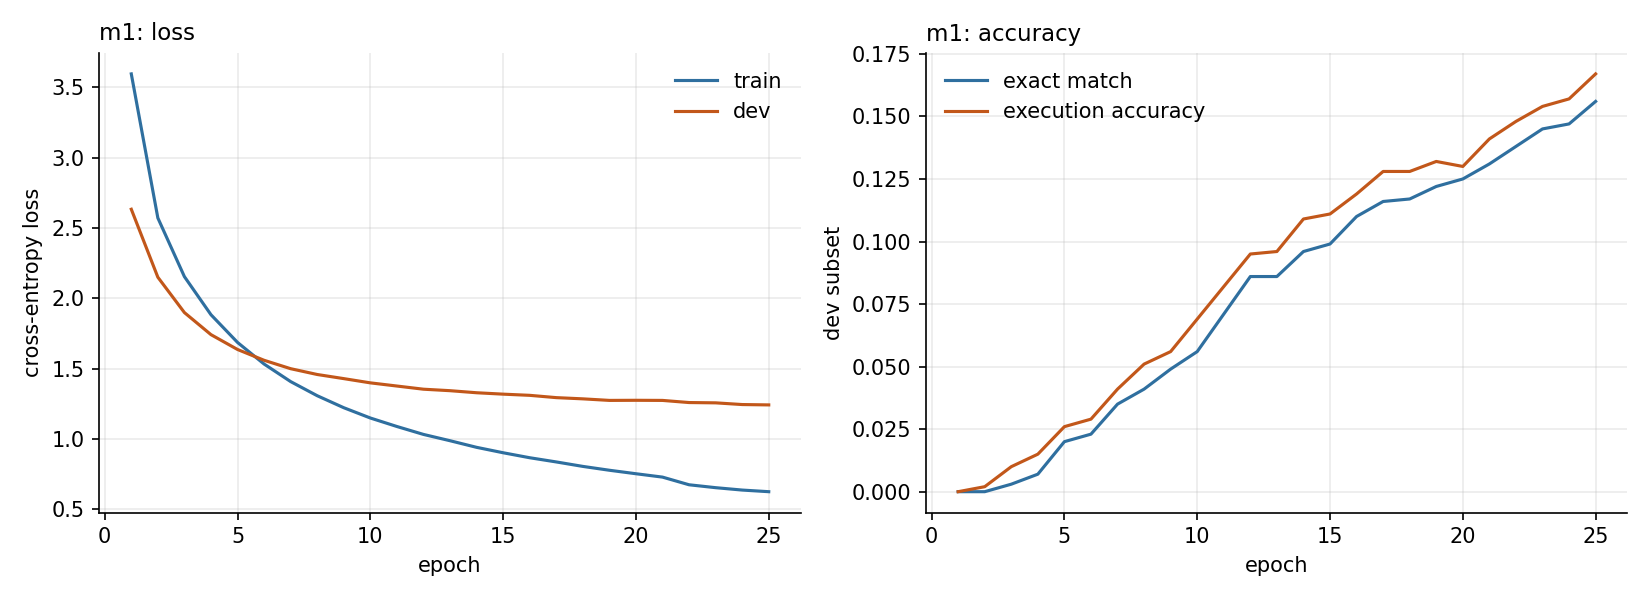

In [64]:
from IPython.display import Image
Image("results/m1/curves.png")

**What I observe.**

- **Loss.** The training loss falls from 3.6 to 0.62. The dev loss falls from 2.6 to 1.24 and flattens after about 10 epochs; it never goes back up. After epoch 6 the two curves separate (0.62 against 1.24 at the end): a generalization gap, which is expected because the dev tables are new tables with new column names and values. The gap is mild and not harmful: the dev loss does not rise, so early stopping was never triggered and the best epoch is the last one.
- **Dev below train at the start.** In the first epochs the dev loss is lower than the training loss. The training loss is an average over the whole epoch, while the model is still improving, and dropout is active during training but not when I measure the dev loss.
- **Accuracy.** On the 1,000 dev questions used after each epoch, exact match rises almost in a straight line to about 15.6% and execution accuracy to about 16.7%. They had not flattened after 25 epochs, so the training budget, not early stopping, ended the run. The dev loss flattens while the accuracy still rises because the loss includes the words the model cannot write (words not in the vocabulary), which keep it high, while the accuracy only needs the best choice to be right.
- **Final result on the full dev set.** Exact match 17.4%, execution accuracy 22.3% (19.9% if the questions whose gold answer is empty are left out), token accuracy 79.8%, perplexity 3.46 (it started at 15,962). The baseline M0 gets 0.0%, so M1 clearly learns.
- **Why exact match is so much lower than token accuracy.** A query has about 13 tokens, and one wrong token (a column name, a value) makes the whole query wrong. In addition, 27.6% of the outputs are not valid queries (valid format 72.4%): the model writes a column name that does not exist, or breaks the format, which is the unknown-word limit found in notebook 02.
- **Execution accuracy above exact match.** Two reasons: a different query can give the same answer, and a wrong query that also returns an empty answer counts as correct (2.4 points of the 22.3%).

### M1b: bidirectional encoder

In [ ]:
import yaml
from t2s.train import train
cfg_m1b = yaml.safe_load((Path(CODE) / "configs/m1b.yaml").read_text())
result_m1b = train(cfg_m1b, data_dir, results_dir="results", ckpt_dir=CKPT_DIR, resume=True)

m1b: 14,115,418 parameters, vocabulary 15,962, 56,355 training examples, device cuda
resumed after epoch 20
epoch 22 | train loss 0.696 | dev loss 1.301 | dev token acc 0.787 | subset exact 0.134 | subset exec 0.144 | 46s *
epoch 23 | train loss 0.678 | dev loss 1.297 | dev token acc 0.789 | subset exact 0.138 | subset exec 0.148 | 48s *
epoch 24 | train loss 0.656 | dev loss 1.292 | dev token acc 0.791 | subset exact 0.142 | subset exec 0.151 | 52s *


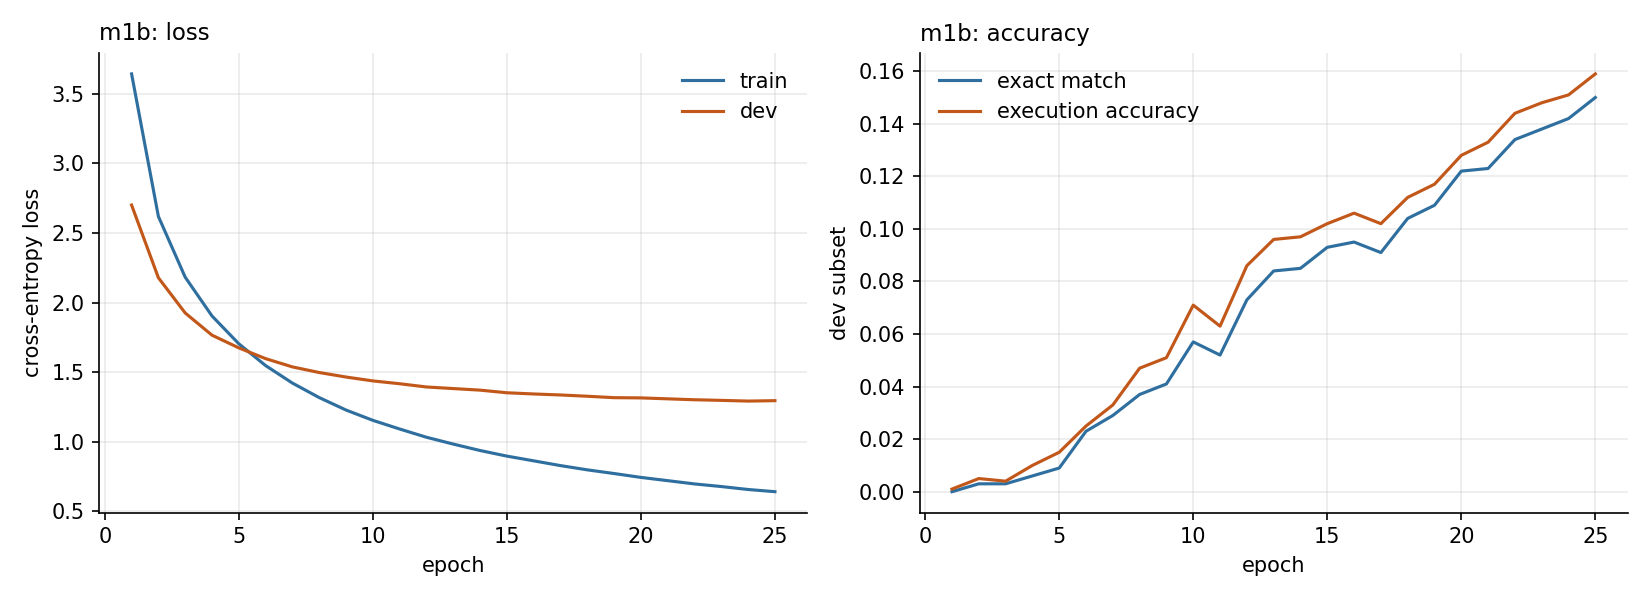

In [67]:
from IPython.display import Image

Image("results/m1b/curves.png")

**What I observe.**

- **Loss.** The curves have the same shape as for M1: the training loss falls to about 0.64, and the dev loss falls to about 1.3 and then flattens, without rising. In the last epochs the dev loss is still improving slowly (1.301, 1.297, 1.292 for the epochs 22, 23 and 24) and the exact match on the dev subset still increases (13.4%, 13.8%, 14.2%). So the model has a generalization gap but does not overfit in the harmful sense.
- **Accuracy.** Exact match and execution accuracy on the dev subset rise steadily, with more irregularities than for M1, and reach about 15.0% and 15.9% after 25 epochs. They were still rising, so this model also was limited by the training budget.
- **Comparison with M1.** Reading the input in both directions did **not** help. At the same epoch, M1b has a higher dev loss (1.29 against 1.24 for M1) and a slightly lower exact match on the subset (about 15.0% against 15.6%). M1b also has more parameters (14.1 million against 13.3 million).
- **Possible reasons.** Without attention the decoder still starts from one vector. For M1b this vector is built from the two directions by a linear layer (the bridge), which may be harder to learn than the simple final state of M1. Also, the difference is small (about one point) and could be within the noise of a single run. Notebook 06 measures it with a paired bootstrap on the test set.
- **What to expect next.** If the bottleneck is the problem, attention (M2, notebook 04), which gives the decoder access to every input position, should help more than a bidirectional encoder alone.

## 11. Comparison on the dev set

In [68]:
import pandas as pd

rows = []
for name in ["m0", "m1", "m1b"]:
    result = json.loads(Path(f"results/{name}/metrics.json").read_text())
    dev = result["dev"]
    rows.append({
        "model": name,
        "parameters": f"{result['parameters']:,}",
        "exact match": round(dev["exact_match"], 4),
        "execution accuracy": round(dev["execution_accuracy"], 4),
        "valid format": round(dev["valid_format"], 4),
        "token accuracy": round(dev.get("token_accuracy", float("nan")), 4),
        "perplexity": round(dev.get("perplexity", float("nan")), 2),
        "best epoch": result.get("best_epoch", "-"),
    })
comparison = pd.DataFrame(rows).set_index("model")
Path("results/phase3_lstm").mkdir(parents=True, exist_ok=True)
comparison.to_csv("results/phase3_lstm/comparison.csv")
comparison

,parameters,exact match,execution accuracy,valid format,token accuracy,perplexity,best epoch
model,,,,,,,
m0,0,0.0000,0.0001,1.0000,NaN,NaN,-
m1,"13,326,426",0.1744,0.2225,0.7239,0.7975,3.46,25
m1b,"14,115,418",0.1644,0.2107,0.6990,0.7913,3.64,24


**What I observe.**

| | M0 | M1 | M1b |
|---|---|---|---|
| Parameters | 0 | 13.3 M | 14.1 M |
| Exact match | 0.0% | **17.4%** | 16.4% |
| Execution accuracy | 0.01% | **22.3%** | 21.1% |
| Valid format | 100% | **72.4%** | 69.9% |
| Token accuracy | – | **79.8%** | 79.1% |
| Perplexity | – | **3.46** | 3.64 |

- **Learning is necessary.** M0, which does not read the question, gets 0.0% exact match. M1 and M1b get 17.4% and 16.4%. M0 always writes a valid query (100%) but never the right one; the trained models are right in a part of the cases, but 28 to 30% of their outputs are not valid queries.
- **The bidirectional encoder did not help.** M1b is slightly **worse** than M1 on every metric: exact match by 1.0 point, execution accuracy by 1.2 points, valid format by 2.5 points, and its perplexity is higher (3.64 against 3.46). It also has about 0.8 million more parameters (+6%). So reading the input in both directions, without attention, brings nothing here.
- **How sure is this?** On 8,421 dev questions, the uncertainty of an accuracy around 17% is about ±0.8 points, so a difference of 1.0 point is of the size of the noise of a single run. I cannot claim that M1b is worse; I can say that it is not better. The paired bootstrap on the test set (notebook 06) will tell.
- **Why the result is plausible.** Both models still compress the whole input into one vector before the decoder starts. A second reading direction gives a better summary, but a summary of 256 numbers remains the bottleneck for an input of 32 tokens on average, and the bridge layer that merges the two directions adds one more thing to learn.
- **Both are limited by the same problem.** The models are far from the ceiling of about 62% for a model that writes words from the vocabulary, and their invalid outputs (28 to 30%) show that they often write column names or values wrongly. The next notebooks address this with attention (M2), which lets the decoder look at every input word, and with copying (M3), which lets it write words that are not in its vocabulary.
- **The execution accuracy is about 4.7 points above the exact match** for both models: some different queries give the same answer, and some wrong queries also return an empty answer (see notebook 01).
- **Best epoch.** The best epoch is the last or almost the last one (25 for M1, 24 for M1b): both were still improving when the budget of 25 epochs ended.

## 12. Examples from the dev set

The predictions of M1b on the first dev questions: some correct, some wrong.

In [69]:
from t2s.evaluate import decode_examples
from t2s.eval.metrics import score
from t2s.train import load_checkpoint

model, codec, cfg = load_checkpoint(f"{CKPT_DIR}/m1b/best.pt", device)
sample = splits["dev"][:300]
outputs = decode_examples(model, sample, codec, device)
_, predictions = score(sample, outputs, dev_executor)

def show(ex, p):
    print("Question :", ex.question.strip())
    print("Gold     :", ex.query.to_sql(ex.header))
    print("Predicted:", p.query.to_sql(ex.header) if p.query else "(invalid) " + " ".join(p.tokens))
    print(f"exact match: {p.exact} | same answer: {p.correct}")
    print()

right = [(e, p) for e, p in zip(sample, predictions) if p.exact]
wrong = [(e, p) for e, p in zip(sample, predictions) if not p.exact]
print(f"in these {len(sample)} questions: {len(right)} exact matches, {len(wrong)} not\n")
print("=== correct ===")
for e, p in right[:4]: show(e, p)
print("=== wrong ===")
for e, p in wrong[:6]: show(e, p)

in these 300 questions: 32 exact matches, 268 not

=== correct ===
Question : What school did player number 21 play for?
Gold     : SELECT School/Club Team FROM table WHERE No. = '21'
Predicted: SELECT School/Club Team FROM table WHERE No. = '21'
exact match: True | same answer: True

Question : Who is the player that wears number 42?
Gold     : SELECT Player FROM table WHERE No. = '42'
Predicted: SELECT Player FROM table WHERE No. = '42'
exact match: True | same answer: True

Question : What are the total number of positions on the Toronto team in 2006-07?
Gold     : SELECT COUNT(Position) FROM table WHERE Years in Toronto = '2006-07'
Predicted: SELECT COUNT(Position) FROM table WHERE Years in Toronto = '2006-07'
exact match: True | same answer: True

Question : what's the aggregate where 1st leg is 3–2
Gold     : SELECT Aggregate FROM table WHERE 1st leg = '3–2'
Predicted: SELECT Aggregate FROM table WHERE 1st leg = '3–2'
exact match: True | same answer: True

=== wrong ===
Question 

**What I observe.**

In these 300 questions, M1b gets 32 exact matches (10.7%). This is lower than its 16.4% on the whole dev set because these are the **first** 300 questions of the dev file, which come from only a few tables (many from the same basketball table); they are not a random sample.

**The correct examples** are simple: one condition, a short value, and a column name that is easy to find (`number 21`, `number 42`, `2006-07`, `3–2`). The model also gets the structure of a query right (aggregator `COUNT`, the order of the parts).

**The mistakes fall into a few clear kinds:**

1. **Words it cannot write (the limit found in notebook 02).** For `Westchester High School` and `Amir Johnson` the model chooses the right column but writes the value `<unk>` (or `<unk> <unk>`), because these words are not in its vocabulary. `<unk>` can never be the right value.
2. **A plausible word taken from training instead of the input.** For `butler cc (ks)` the model wrote `Player = 'jawann oldham ( pie )'`: another column and a value that looks like a value it saw in training. For the question about the 2005-06 season it wrote the column name `years in orlando` instead of `years in toronto`, which is not a column of this table, so the output is **invalid**. The model does not copy from the question or from the list of columns; it generates a word that is likely in general. This is the kind of error that attention and the copy mechanism should reduce.
3. **A missing condition.** For `guard for toronto in 1996-97` the model wrote only the condition on the years and left out `Position = 'Guard'`. Its value for the years is also wrong (`1996 - 1996`, while the question says `1996-97`): the model repeats a number instead of copying the right one.
4. **A wrong query that gives the right answer.** `COUNT(Nationality)` instead of `COUNT(School/Club Team)` is not the gold query (exact match: False), but both give the same answer (1) because the count of any column, for the rows where `No. = 3`, is the same. It shows why I report both exact match and execution accuracy.

**Summary.** Most of the mistakes are about the **content** of the query (columns and values that are new or unknown), and not about its **structure**. This is consistent with the numbers: a token accuracy of about 79% but only about 16% exact match, and 30% of the outputs that are not valid queries.

## Appendix: training from the command line

The same training can be started from a terminal, and any value of the config can be changed on the command line. This is how I run
the experiments with other settings, for example:

`python {CODE}/scripts/train.py --config {CODE}/configs/m1.yaml --set model.hidden=128 name=m1_h128`

**The start of the script:** its description, the imports, and the path to the project code.

In [70]:
%%writefile {CODE}/scripts/train.py
"""Train one model from a config file.

Usage:
    python scripts/train.py --config configs/m1.yaml
    python scripts/train.py --config configs/m1.yaml --set model.hidden=128 name=m1_h128

`--set` changes single values of the config (the changed config is saved with the results).
"""

import argparse
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "src"))

import yaml  # noqa: E402

from t2s.train import train  # noqa: E402




Writing /content/code/scripts/train.py


**`parse_value`** reads a value typed on the command line. YAML reads `5e-4` as text, not as a number, so a number is tried first.

In [71]:
%%writefile -a {CODE}/scripts/train.py
def parse_value(raw: str):
    """Read a value from the command line. YAML reads 5e-4 as text, so try a float first."""
    try:
        return float(raw) if any(ch in raw for ch in "eE.") else yaml.safe_load(raw)
    except ValueError:
        return yaml.safe_load(raw)




Appending to /content/code/scripts/train.py


**`apply_overrides`** changes values of the config (`model.hidden=128` changes `config["model"]["hidden"]`). A key that does not exist is an
error, so a typing mistake cannot go unnoticed.

In [72]:
%%writefile -a {CODE}/scripts/train.py
def apply_overrides(cfg: dict, overrides: list[str]) -> dict:
    for item in overrides:
        key, _, raw = item.partition("=")
        target = cfg
        *path, last = key.split(".")
        for part in path:
            target = target[part]
        if last not in target:
            raise KeyError(f"unknown config key: {key}")
        target[last] = parse_value(raw)
    return cfg




Appending to /content/code/scripts/train.py


**`main`** reads the arguments, loads the config, applies the changes, and calls `train`.

In [73]:
%%writefile -a {CODE}/scripts/train.py
def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    parser.add_argument("--config", required=True)
    parser.add_argument("--data-dir", default="data/wikisql")
    parser.add_argument("--results-dir", default="results")
    parser.add_argument("--ckpt-dir", default=None, help="where checkpoints go (for example a Google Drive folder)")
    parser.add_argument("--resume", action="store_true", help="continue from the last saved epoch")
    parser.add_argument("--limit-train", type=int, default=None, help="use only the first N training examples (quick tests)")
    parser.add_argument("--set", nargs="*", default=[], metavar="KEY=VALUE")
    args = parser.parse_args()

    cfg = apply_overrides(yaml.safe_load(Path(args.config).read_text()), args.set)
    train(cfg, args.data_dir, args.results_dir, args.ckpt_dir, args.resume, args.limit_train)




Appending to /content/code/scripts/train.py


**The entry point.**

In [74]:
%%writefile -a {CODE}/scripts/train.py
if __name__ == "__main__":
    main()


Appending to /content/code/scripts/train.py


## Summary of this notebook

**What I built:** the metrics (exact match, execution accuracy), the baseline M0, an LSTM cell written from its equations and tested against
PyTorch's, the encoder, the decoder, the `Seq2Seq` model (with or without a bidirectional encoder), greedy decoding, the training loop with
early stopping, checkpoints and resume, and the configs of the experiments.

**Checks before training:** the first loss (9.70) is the expected `ln(V)` (9.68); the model can memorize a batch; my cell equals PyTorch's; the
padding does not change the encoding.

**Next notebook:** `04_attention.ipynb` adds the attention mechanism to remove the bottleneck between the encoder and the decoder.